# Seeds and other changes to the junction finder, on 138 hand-drawn sections

The junction finder places one **seed** in each organoid and cuts the tissue between them. Until now it was tested on 30 hand-drawn sections. There are now **138** sections whose junction was drawn by hand, so the finder can be tested far more reliably — and the question raised by the failed section 034-033_s17 can be answered: there, the labelled seed covered only one of two dense patches of AF488 cells, and with a seed covering both the line moved from 341 µm to 17 µm from the hand-drawn one. Does that hold in general, and do other settings help?

**What is compared** (`junction_seeding.py`; every variant changes one thing from today's defaults):

| Variant | What changes |
|---|---|
| seeds: all labelled patches | the labelled seed is **every** patch of AF488 cells above half the density range and at least 2 % of the tissue, not only the largest; not pulled back |
| seeds: all patches, each pulled back | the same, each patch then cut to its own half furthest from the other seed |
| seeds: dominant (lead 0.15 / 0.25 / 0.35) | each seed is all tissue where its own label outweighs the other by at least the lead (scaled 0–1) |
| seeds: second seed without AF555 | the other seed is the AF488-poor tissue far from the labelled seed, ignoring AF555 |
| bend 400 / 2000 / 3000 | the price of a sharp turn in the line (default 1000 µm) |
| tears priced | cutting along a tear costs as much as plain tissue |
| cells' edge 0.5 | cutting costs more where the labels are at either organoid's own level |
| no-seam fallback | where the cut has no dark line under it, redo it from dominant seeds |
| tissue from the nuclear stain only | the old tissue mask (a check that the change of 22 October still helps) |
| all patches + tears priced, all patches + bend 2000 | two combinations |

**How it is scored.** For each section the mean distance (µm) between the finder's line and the hand-drawn line, over the tissue, **capped at 300 µm** (no line at all counts 300). A line more than 100 µm off is called a **bad line**.

**Default** here means the defaults of 26 October 2026 *before* this notebook turned the no-seam fallback on (`junction_seeding.BASE`); the fallback is the variant "no-seam fallback".

**Tuning and held-out sections.** The first 30 keep their split from `junction_evaluation`; the 108 new ones are split the same way (a third held out, balanced across the pre-screen's Ripped / Folded / Quality classes). The rule of the project: a default changes only if the **held-out** sections improve.

In [1]:
import ssl

# Some Python installations on Windows cannot read the Windows certificate store.
try:
    ssl.create_default_context()
except ssl.SSLError:  # pragma: no cover - machine-specific
    ssl.SSLContext._load_windows_store_certs = lambda self, storename, purpose: None

import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd().resolve()
while not (ROOT / "microscopy_viewer").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "notebooks" / "validation"))
import junction_tuning as jt
from microscopy_viewer import junction as jn

OUT = jt.OUT
res = pd.read_json(OUT / "seeding.jsonl", lines=True)
diag = pd.read_csv(OUT / "seeding_diagnostics.csv")
samples = pd.read_csv(OUT / "annotated_all.csv")
import junction_seeding as js
VARIANTS = [v for v in js.VARIANTS if v in set(res["variant"])]
BAD = 100.0
print(f"{res['name'].nunique()} sections × {len(VARIANTS)} variants = {len(res)} runs")
display(pd.crosstab(samples["batch"], samples["set"], margins=True))
print("pre-screen classes of the 138:")
for c in ("Ripped", "Folded", "Quality", "Shape"):
    print(f"  {c}: " + ", ".join(f"{k} {v}" for k, v in samples[c].fillna("(none)").value_counts().items()))

138 sections × 21 variants = 2898 runs


set,held out,tuning,All
batch,,,
first 31,8,22,30
new,37,71,108
All,45,93,138


pre-screen classes of the 138:
  Ripped: no 79, yes 51, review 8
  Folded: no 78, yes 52, review 8
  Quality: Moderate 60, Good 59, Bad 19
  Shape: Fused pair 123, Damaged 13, Separated 2


## 1. Every variant, side by side

Capped mean error on the tuning sections, the held-out sections and all of them; the median error; the share of bad lines (> 100 µm off); sections with no line at all; the median HD95 (the distance within which 95 % of the line lies).

In [2]:
def summary(frame):
    g = frame.groupby("variant")
    return pd.DataFrame({
        "capped mean, tuning": frame[frame["set"] == "tuning"].groupby("variant")["capped"].mean(),
        "capped mean, held out": frame[frame["set"] == "held out"].groupby("variant")["capped"].mean(),
        "capped mean, all": g["capped"].mean(),
        "median": g["capped"].median(),
        "bad lines (%)": g["capped"].apply(lambda s: (s > BAD).mean() * 100),
        "no line": g["found"].apply(lambda s: int((~s.fillna(False).astype(bool)).sum())),
        "median HD95": g["hd95"].median(),
    }).loc[VARIANTS]


table = summary(res)
display(table.round(1))
print("the first 31 alone (comparable with junction_evaluation):")
display(summary(res[res["batch"] == "first 31"])[["capped mean, tuning", "capped mean, held out", "capped mean, all", "bad lines (%)"]].round(1))

,"capped mean, tuning","capped mean, held out","capped mean, all",median,bad lines (%),no line,median HD95
variant,,,,,,,
default,141.6,172.0,151.5,119.4,55.8,2,274.0
seeds: all labelled patches,174.4,181.3,176.7,199.4,61.6,2,347.4
"seeds: all patches, each pulled back",152.1,176.9,160.2,125.5,57.2,2,308.4
seeds: dominant (lead 0.15),131.6,150.9,137.9,106.8,52.9,2,214.5
seeds: dominant (lead 0.25),128.1,145.9,133.9,107.1,52.2,2,217.5
seeds: dominant (lead 0.35),126.5,139.8,130.8,92.7,46.4,2,192.9
seeds: second seed without AF555,139.2,165.3,147.7,113.7,53.6,1,229.2
bend 400,129.9,162.1,140.4,104.0,50.0,2,231.4
bend 2000,152.3,175.1,159.7,138.9,60.9,2,271.2


the first 31 alone (comparable with junction_evaluation):


,"capped mean, tuning","capped mean, held out","capped mean, all",bad lines (%)
variant,,,,
default,49.3,116.4,67.2,16.7
seeds: all labelled patches,102.1,124.0,107.9,33.3
"seeds: all patches, each pulled back",75.3,109.7,84.5,23.3
seeds: dominant (lead 0.15),91.4,129.3,101.5,30.0
seeds: dominant (lead 0.25),80.1,96.1,84.4,26.7
seeds: dominant (lead 0.35),68.2,143.7,88.4,23.3
seeds: second seed without AF555,74.6,124.5,87.9,26.7
bend 400,38.2,121.8,60.5,13.3
bend 2000,52.5,106.3,66.9,20.0


## 2. Paired against the default

The same sections, each variant against today's default: the mean change of the capped error (negative = better) with a 95 % bootstrap interval, how many sections it **fixes** (more than 25 µm closer to the hand-drawn line) and **breaks** (more than 25 µm further), and a Wilcoxon signed-rank test. On all 138 sections and on the 45 held out.

sections  mean change (µm)  CI low  CI high  fixed  broken  Wilcoxon p
seeds: all labelled patches          all          138.0            25.152  10.288   40.965   13.0    31.0       0.001
                                     held out      45.0             9.307 -17.741   38.563    9.0     7.0       0.864
seeds: all patches, each pulled back all          138.0             8.674  -4.531   22.526   14.0    12.0       0.368
                                     held out      45.0             4.938 -21.361   34.955    7.0     4.0       0.744
seeds: dominant (lead 0.15)          all          138.0           -13.625 -34.396    6.826   48.0    36.0       0.314
                                     held out      45.0           -21.088 -53.493   10.072   15.0    12.0       0.307
seeds: dominant (lead 0.25)          all          138.0           -17.627 -34.281   -0.801   39.0    27.0       0.054
                                     held out      45.0           -26.098 -50.948   -4.781   12.0     8.0       0.051
seeds: dominant (lead 0.35)          all          138.0           -20.728 -35.549   -5.337   41.0    21.0       0.006
                                     held out      45.0           -32.226 -60.074   -8.017   15.0     7.0       0.025
seeds: second seed without AF555     all          138.0            -3.826 -24.435   17.169   38.0    35.0       0.755
                                     held out      45.0            -6.704 -45.331   32.073   14.0    13.0       0.613
bend 400                             all          138.0           -11.094 -19.667   -3.099   25.0     8.0       0.061
                                     held out      45.0            -9.845 -22.492   -0.326    6.0     1.0       0.829
bend 2000                            all          138.0             8.201  -3.003   19.706   12.0    21.0       0.034
                                     held out      45.0             3.072 -20.314   24.155    7.0    10.0       0.361
bend 3000                            all          138.0            10.546  -1.306   22.555   16.0    27.0       0.020
                                     held out      45.0            18.274  -0.787   38.186    5.0    12.0       0.058
tears priced                         all          138.0           -12.011 -24.512    0.407   24.0    13.0       0.337
                                     held out      45.0            -4.395 -28.207   20.055    9.0     7.0       0.953
cells' edge 0.5                      all          138.0            25.520  12.110   39.718   13.0    32.0       0.001
                                     held out      45.0            10.279 -10.224   30.495    7.0     8.0       0.545
no-seam fallback                     all          138.0           -12.372 -24.051   -0.305   21.0    10.0       0.036
                                     held out      45.0           -13.401 -27.556   -2.405    6.0     1.0       0.033
tissue from the nuclear stain only   all          138.0            16.834   3.527   30.468   16.0    28.0       0.178
                                     held out      45.0            20.445  -5.114   48.638    6.0     9.0       0.469
all patches + tears priced           all          138.0            15.366  -3.010   32.555   21.0    39.0       0.016
                                     held out      45.0            15.701 -18.228   49.594    8.0    12.0       0.331
all patches + bend 2000              all          138.0            29.168  12.111   46.231   16.0    39.0       0.000
                                     held out      45.0            17.135 -14.108   49.151   10.0    11.0       0.337
no-seam fallback, lead 0.35          all          138.0           -12.555 -24.530    0.068   21.0     9.0       0.043
                                     held out      45.0           -17.147 -37.151    1.517    6.0     2.0       0.091
no-seam fallback, no cells' edge     all          138.0           -10.342 -22.100    0.519   20.0    11.0       0.075
                                   

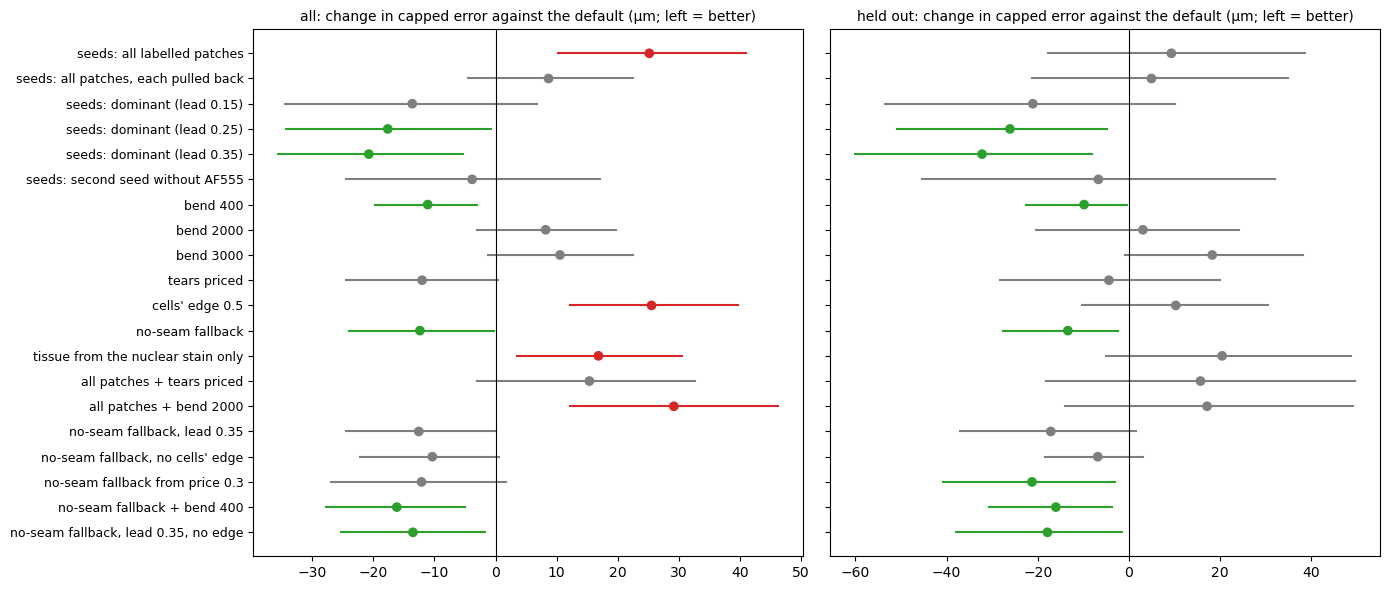

In [3]:
wide = res.pivot(index="name", columns="variant", values="capped")
set_of = samples.set_index("name")["set"].reindex(wide.index)
rng = np.random.default_rng(0)
rows = {}
for v in VARIANTS[1:]:
    change = wide[v] - wide["default"]
    for part, idx in (("all", wide.index), ("held out", wide.index[set_of == "held out"])):
        x = change.loc[idx].dropna().to_numpy()
        boot = [rng.choice(x, len(x)).mean() for _ in range(2000)]
        rows[(v, part)] = {"sections": len(x), "mean change (µm)": x.mean(),
                           "CI low": np.percentile(boot, 2.5), "CI high": np.percentile(boot, 97.5),
                           "fixed": int((x < -25).sum()), "broken": int((x > 25).sum()),
                           "Wilcoxon p": stats.wilcoxon(x).pvalue if np.any(x != 0) else np.nan}
paired = pd.DataFrame(rows).T
display(paired.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
y = np.arange(len(VARIANTS) - 1)[::-1]
for ax, part in zip(axes, ("all", "held out")):
    p = paired.xs(part, level=1).loc[VARIANTS[1:]]
    colours = ["tab:green" if hi < 0 else "tab:red" if lo > 0 else "tab:grey" for lo, hi in zip(p["CI low"], p["CI high"])]
    for yi, (m, lo, hi, c) in enumerate(zip(p["mean change (µm)"], p["CI low"], p["CI high"], colours)):
        ax.plot([lo, hi], [y[yi], y[yi]], color=c, lw=1.5)
    ax.scatter(p["mean change (µm)"], y, c=colours, zorder=3)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"{part}: change in capped error against the default (µm; left = better)", fontsize=10)
axes[0].set_yticks(y, VARIANTS[1:], fontsize=9)
fig.tight_layout()
plt.show()

## 3. By pre-screen class

The default and the three variants with the lowest capped mean on all sections, split by the pre-screen's classes and by batch (the first 31 against the new ones): does a variant help everywhere, or only on some kinds of section?

In [4]:
best = list(table["capped mean, all"].drop("default").nsmallest(3).index)
show = ["default", *best]
cls = samples.set_index("name")
long = res[res["variant"].isin(show)].copy()
for c in ("Ripped", "Folded", "Quality", "batch"):
    long[c] = long["name"].map(cls[c]).fillna("(none)")
for c in ("Ripped", "Folded", "Quality", "batch"):
    t = long.pivot_table(index=c, columns="variant", values="capped", aggfunc="mean")[show]
    t.insert(0, "sections", long[long["variant"] == "default"].groupby(c).size())
    print(f"capped mean by {c}:")
    display(t.round(1))

capped mean by Ripped:


variant,sections,default,seeds: dominant (lead 0.35),seeds: dominant (lead 0.25),no-seam fallback + bend 400
Ripped,,,,,
no,79,151.6,125.1,134.9,129.2
review,8,158.6,122.2,109.9,112.4
yes,51,150.3,140.9,136.1,148.5


capped mean by Folded:


variant,sections,default,seeds: dominant (lead 0.35),seeds: dominant (lead 0.25),no-seam fallback + bend 400
Folded,,,,,
no,78,154.8,136.0,136.7,139.3
review,8,158.9,64.9,155.7,135.3
yes,52,145.4,133.2,126.4,129.5


capped mean by Quality:


variant,sections,default,seeds: dominant (lead 0.35),seeds: dominant (lead 0.25),no-seam fallback + bend 400
Quality,,,,,
Bad,19,176.2,155.2,136.9,162.7
Good,59,146.0,126.9,138.5,128.2
Moderate,60,149.1,126.9,128.4,133.8


capped mean by batch:


variant,sections,default,seeds: dominant (lead 0.35),seeds: dominant (lead 0.25),no-seam fallback + bend 400
batch,,,,,
first 31,30,67.2,88.4,84.4,71.0
new,108,175.0,142.6,147.7,153.3


## 4. What the seeds tell us

With the defaults: how many separate dense patches of AF488 cells each section has (each at least 2 % of the tissue), how much of the tissue the labelled seed covers, how far apart the seeds are, and whether a seed lies **inside the hand-drawn band** — the band is in the organoid AF488 does not come from, so a labelled seed there is in the wrong organoid from the start.

In [5]:
d = diag.merge(wide[["default"]].rename(columns={"default": "error"}), left_on="name", right_index=True)
for v in ("seeds: all labelled patches", "seeds: all patches, each pulled back"):
    if v in wide:
        d[v] = d["name"].map(wide[v] - wide["default"])
d["patches"] = d["AF488 patches"].clip(upper=3).map({1: "1", 2: "2", 3: "3 or more"}).fillna("none")
by = d.groupby("patches").agg(sections=("name", "size"), default_error=("error", "mean"),
                              bad_lines=("error", lambda s: int((s > BAD).sum())),
                              **{f"change, {v.split(': ')[1]}": (v, "mean") for v in ("seeds: all labelled patches", "seeds: all patches, each pulled back") if v in d})
print("by number of dense AF488 patches:")
display(by.round(1))
wrong = d["labelled seed in the hand-drawn band"] > 0.2
print(f"labelled seed mostly inside the hand-drawn band (the wrong organoid): {int(wrong.sum())} sections, "
      f"default error {d.loc[wrong, 'error'].mean():.0f} µm against {d.loc[~wrong, 'error'].mean():.0f} µm for the rest")
rho = {}
for c in ("AF488 patches", "labelled seed (share of tissue)", "other seed (share of tissue)", "seed distance (um)",
          "Seam price", "Density contrast", "Labelled share of tissue", "Solidity", "Hole share"):
    r = stats.spearmanr(d[c], d["error"], nan_policy="omit")
    rho[c] = {"Spearman with the default's error": r[0], "p": r[1]}
display(pd.DataFrame(rho).T.round(3))
print("second seed rule used:", d["second seed rule"].value_counts().to_dict())

by number of dense AF488 patches:


,sections,default_error,bad_lines,"change, all labelled patches","change, all patches, each pulled back"
patches,,,,,
1,79,149.5,43,12.4,0.0
2,41,153.3,24,27.9,-0.1
3 or more,18,156.5,10,74.8,66.6


labelled seed mostly inside the hand-drawn band (the wrong organoid): 9 sections, default error 246 µm against 145 µm for the rest


,Spearman with the default's error,p
AF488 patches,0.028,0.741
labelled seed (share of tissue),-0.057,0.510
other seed (share of tissue),-0.029,0.739
seed distance (um),-0.064,0.456
Seam price,0.397,0.000
Density contrast,-0.154,0.071
Labelled share of tissue,0.221,0.009
Solidity,0.078,0.362
Hole share,0.095,0.269


second seed rule used: {"dense core of the other organoid's label": 137, 'low-density tissue far from the labelled cells': 1}


## 5. Pictures: where the best seed variant helps and where it hurts

The three sections the best seed variant improves most and the three it makes worst, over the nuclear stain. White dashed: drawn by hand. Magenta: the default. Cyan: the variant.

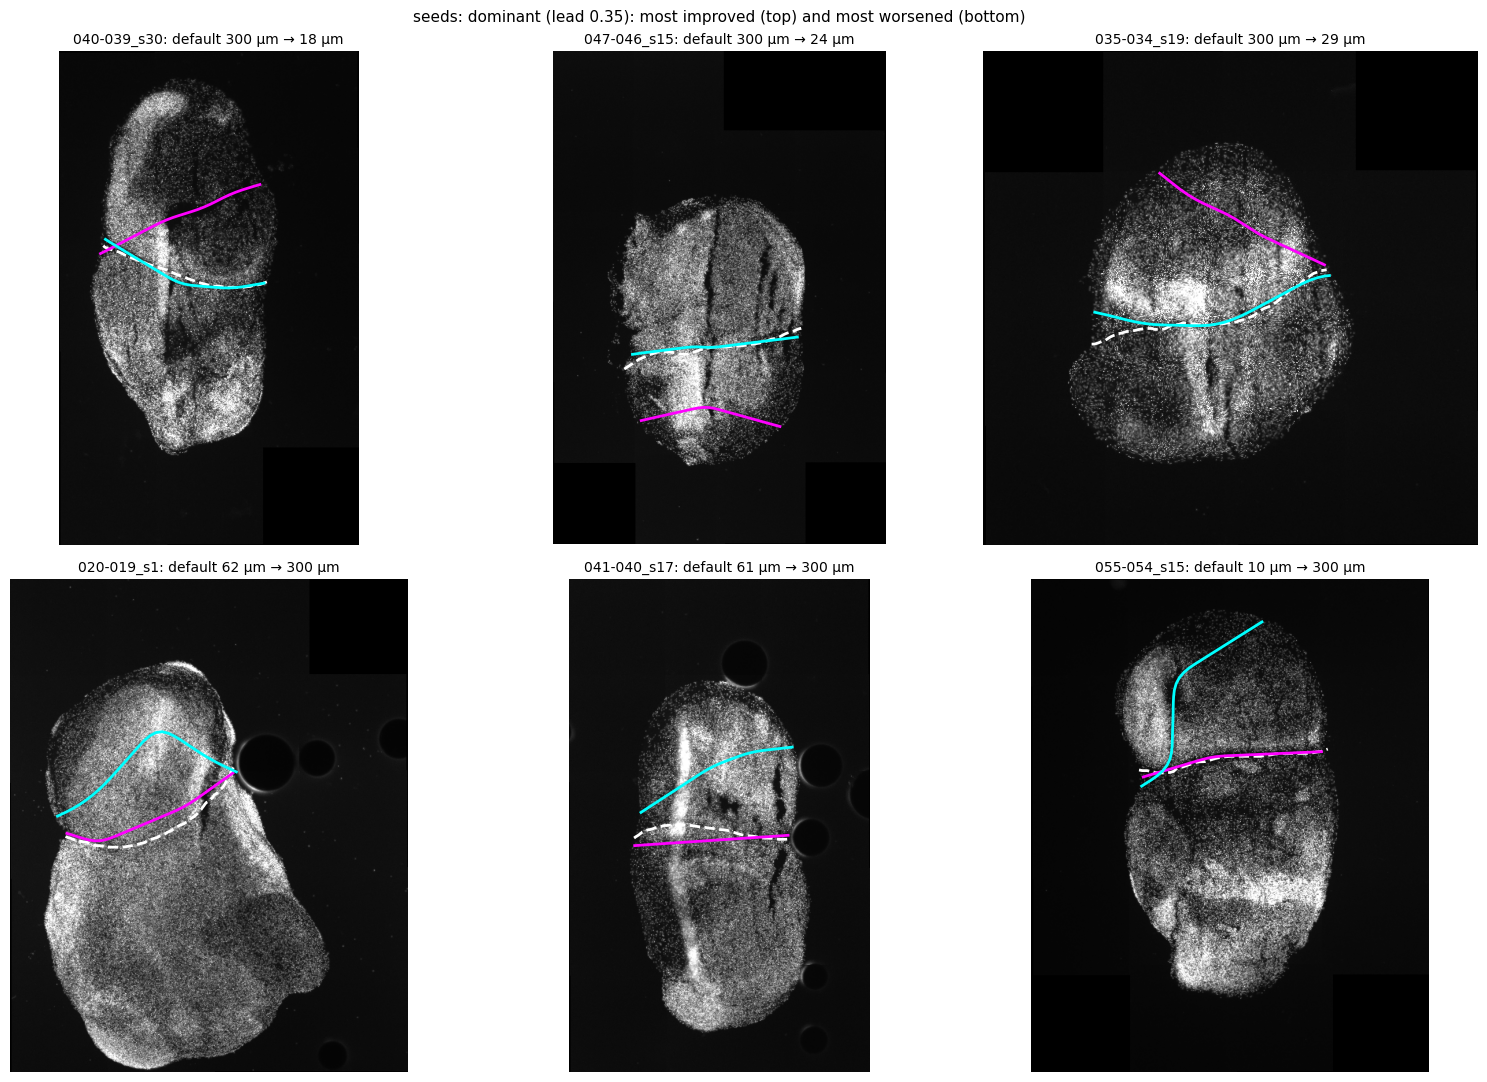

In [6]:
seed_variants = [v for v in VARIANTS if v.startswith("seeds:")]
chosen = min(seed_variants, key=lambda v: table.loc[v, "capped mean, all"])
change = (wide[chosen] - wide["default"]).dropna().sort_values()
show_names = list(change.index[:3]) + list(change.index[-3:])
params = dict(js.VARIANTS)
fig, axes = plt.subplots(2, 3, figsize=(16, 11))
for ax, name in zip(axes.ravel(), show_names):
    ov, band, manual, base = jt.load_case(name)
    stain = ov.channels[ov.nuclear].astype(float)
    ax.imshow(stain, cmap="gray", vmax=np.percentile(stain, 99.5))
    m = manual / ov.um
    ax.plot(m[:, 1], m[:, 0], "w--", lw=2)
    for variant, colour in (("default", "magenta"), (chosen, "cyan")):
        p = dict(params[variant]); lead = p.pop("SEED_LEAD", None)
        saved = jn.SEED_LEAD
        if lead is not None:
            jn.SEED_LEAD = lead
        r = jt.run_case((name, {**jt.defaults(), **js.BASE, **p}))
        jn.SEED_LEAD = saved
        if r.get("line"):
            l = np.asarray(r["line"]) / ov.um
            ax.plot(l[:, 1], l[:, 0], color=colour, lw=2)
    ax.set_title(f"{name.split('_')[-2]}_{name.split('_')[-1]}: default {wide.loc[name, 'default']:.0f} µm → {wide.loc[name, chosen]:.0f} µm", fontsize=10)
    ax.set_axis_off()
fig.suptitle(f"{chosen}: most improved (top) and most worsened (bottom)", fontsize=11)
fig.tight_layout()
plt.show()

### What it showed (26 October 2026)

**The new sections are much harder than the first 30.** With today's defaults the capped error is 67 µm on the first 30 hand-drawn sections but 175 µm on the 108 new ones, and 56 % of all lines are more than 100 µm off. The hand-drawn lines on the new sections look right (pictures checked); the sections themselves often have **no dark line at the junction**, are ring-shaped, or have a bright slide edge beside them. The seam price (mean price under the cut) is the best single warning sign: it correlates with the error (Spearman 0.40), and its median is 0.41 on the new sections against 0.23 on the first 30.

**Seeds.**
- *Every labelled patch as the seed* (the change that fixed 034-033_s17) is **worse** in general: +25 µm, 31 sections broken against 13 fixed, worst on sections with three or more AF488 patches (+75 µm). A second patch is more often a fold or autofluorescence than a second part of the organoid.
- *Dominant seeds* (each seed is all the tissue where its own label clearly leads) help the seamless sections a lot (new: 175 → 143 µm with lead 0.35) but **break the sections that have a dark line** (first 30: 67 → 88 µm). A larger lead (0.35) is better than 0.25 or 0.15. (A bug made the lead setting ineffective in the first run; it was fixed and those variants rerun.)
- The second seed without AF555 and the seeds' size or distance do not matter (no correlation with the error).
- 9 sections have their labelled seed largely inside the hand-drawn band, i.e. in the wrong organoid: their error is 246 µm against 145 µm. Seeding is the cause there, but no seed rule tested fixes them reliably.

**Other settings.** Bend 400 is slightly better on tuning (−11 µm) but not on held-out (−10 µm, p 0.83); bend 2000 / 3000 and the cells' edge are worse; pricing tears helps tuning only. Tissue from the nuclear stain only is worse again (+17 µm): the 22 October change holds on the new sections.

**Decision: the no-seam fallback is now on by default** (`no_seam_price` = 0.4). It uses dominant seeds only where the first cut found no dark line, so it gets most of their benefit where they help and none of the harm: held-out 172 → 159 µm (p 0.03; 6 fixed, 1 broken), all 152 → 139 µm, first 30 unchanged (67 → 66 µm). The follow-up variants (lead 0.35, no cells' edge, threshold 0.3, with bend 400) were chosen against on the tuning sections or did not improve held-out further enough to justify another setting.

**What is left.** Even with the fallback, half the sections are more than 100 µm off; the junction finder is not good enough for sections without a dark line, and those are common in the new slides. Triage stays: draw by hand when status is fail, Shape is Damaged, or the flag *no dark line at the junction* is raised. Next candidates: a seam found from the labels' gradient (where AF488 falls and AF555 rises) as part of the price, rather than only as seeds.

## 6. The change between the two labels in the price (27 October 2026)

Without a dark line, the cut has nothing in the nuclear stain to follow, and the fallback above only moves the seeds. Here the **price** itself learns where the organoids meet: one label falls and the other rises there, dark line or not. `junction.label_change_price` measures the two label densities (smoothed over 50 µm, finer than the 100 µm used for the seeds), scaled 0–1, subtracted; the steeper that map, the cheaper a pixel is to cut: the dark-line price is multiplied by a factor from 1 (labels flat) down to 0.3 (the steepest change, as a share of its 99th percentile, times the strength). Outside the tissue the map takes the nearest tissue value, so the section's edge is not a change.

A tear is dark but the labels do not change across it, so the label factor leaves a dark tear cheap: one variant also prices tears like plain tissue. `junction_labels.py` → `labels.jsonl`; **default is today's** (no-seam fallback on), so the numbers differ from sections 1–5.

In [7]:
import junction_labels as jl

lab = pd.read_json(OUT / "labels.jsonl", lines=True)
LV = [v for v in jl.VARIANTS if v in set(lab["variant"])]
lw = lab.pivot(index="name", columns="variant", values="capped")
held = samples.set_index("name")["set"].reindex(lw.index) == "held out"
first = samples.set_index("name")["batch"].reindex(lw.index) == "first 31"
rows = {}
for v in LV:
    c = lw[v] - lw["default"]
    rows[v] = {"tuning": lw[v][~held].mean(), "held out": lw[v][held].mean(), "all": lw[v].mean(),
               "first 30": lw[v][first].mean(), "new": lw[v][~first].mean(),
               "bad lines, tuning (%)": (lw[v][~held] > BAD).mean() * 100, "bad lines, held out (%)": (lw[v][held] > BAD).mean() * 100,
               "fixed / broken, held out": f"{int((c[held] < -25).sum())} / {int((c[held] > 25).sum())}",
               "Wilcoxon p, held out": stats.wilcoxon(c[held]).pvalue if (c[held] != 0).any() else np.nan}
display(pd.DataFrame(rows).T.round(3))

,tuning,held out,all,first 30,new,"bad lines, tuning (%)","bad lines, held out (%)","fixed / broken, held out","Wilcoxon p, held out"
default,129.747584,158.580324,139.149565,66.249877,159.399478,48.387097,60.0,0 / 0,NaN
change 0.5,127.51256,157.807941,137.391489,64.086669,157.753939,45.16129,62.222222,3 / 3,0.371961
change 1,130.637327,146.204545,135.713594,68.245838,154.454637,44.086022,55.555556,8 / 5,0.125438
change 2,130.26581,163.783399,141.195459,76.97106,159.035569,41.935484,57.777778,5 / 10,0.416743
"change 1, measured at 25 µm",131.723196,152.493863,138.496239,67.377464,158.251455,48.387097,57.777778,6 / 4,0.317589
"change 1, measured at 100 µm",144.435014,160.400631,149.641194,67.800813,172.374633,49.462366,60.0,7 / 8,0.893396
"change 1, no-seam fallback off",140.400954,162.092974,147.474439,69.931574,169.014124,47.311828,60.0,9 / 12,0.643517
change 1 + bend 400,128.455727,158.867183,138.372506,70.879553,157.120549,43.010753,57.777778,4 / 7,0.798912
change 1 + tears priced,117.945983,153.980227,129.69628,65.217614,147.60702,35.483871,51.111111,7 / 8,0.671431
change 2 + tears priced,129.584317,171.015623,143.094526,91.259207,157.493225,43.010753,60.0,5 / 13,0.104903


What the price looks like on two sections: the dark-line price alone, the label factor, and the two together, with the hand-drawn line (white, dashed). The first section has a dark line at the junction; the second does not.

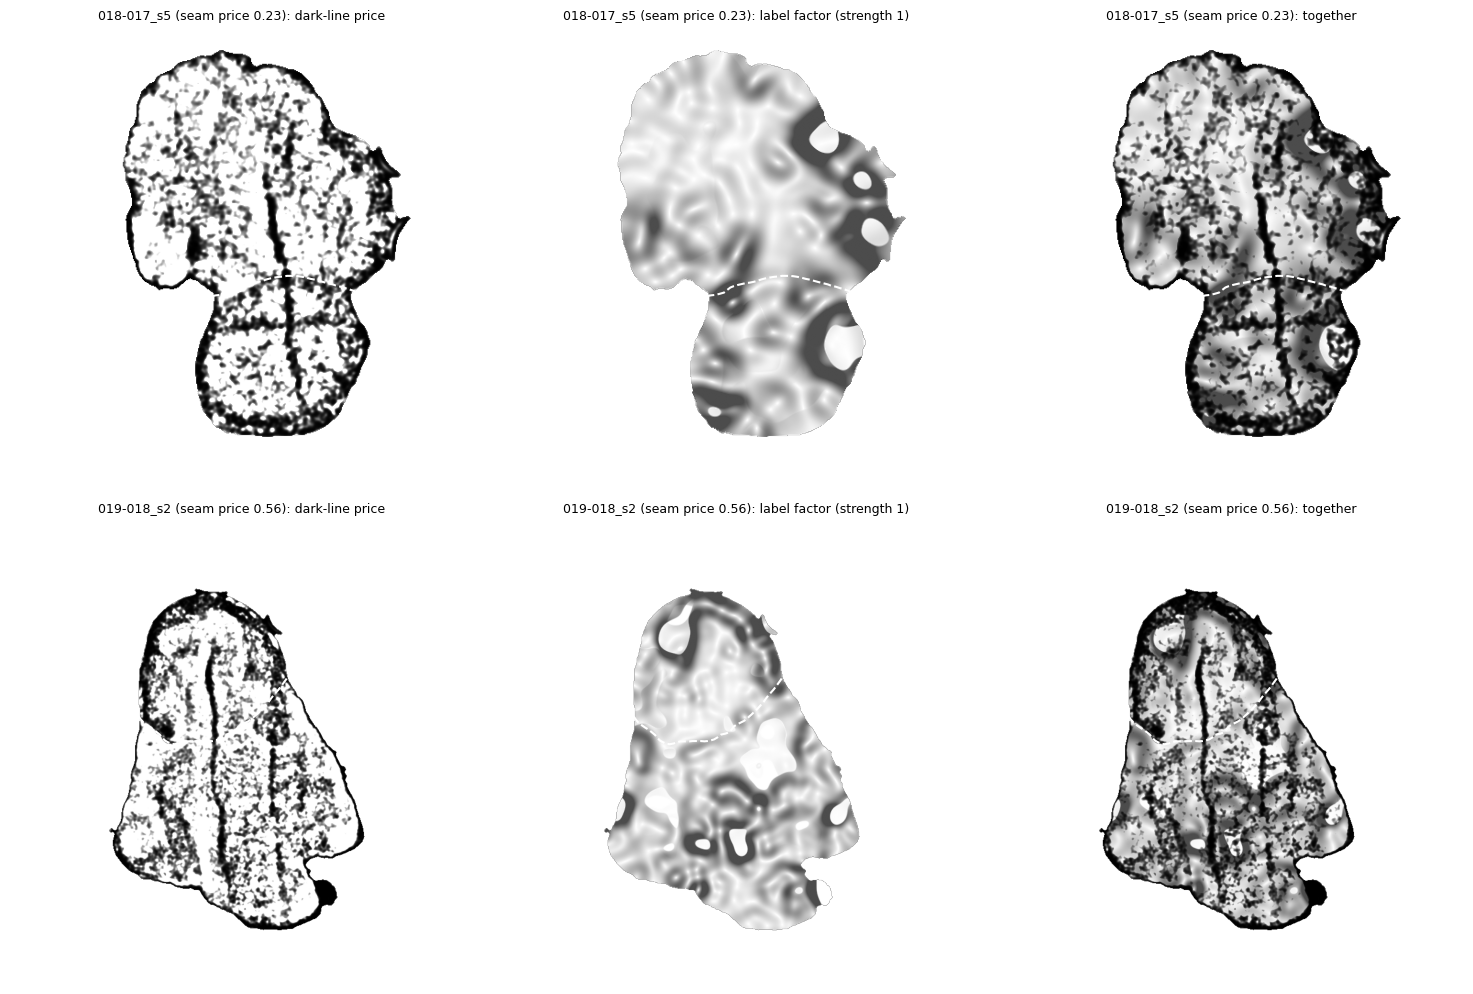

In [8]:
seam_of = diag.set_index("name")["Seam price"]
pair = [seam_of[seam_of < 0.25].index[0], seam_of[seam_of > 0.5].index[0]]
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for row, name in zip(axes, pair):
    ov, band, manual, base = jt.load_case(name)
    ch = ov.channels
    tissue = jn.tissue_mask(ch[ov.nuclear], (ch > 0).all(axis=0), ov.um, jn._others(ch, ov.nuclear, True))
    filled = __import__("scipy").ndimage.binary_fill_holes(tissue)
    stain = ov.nuclear_mean if ov.nuclear_mean is not None else ch[ov.nuclear]
    dark = jn.line_cost(stain, filled, ov.um)
    other = ch[ov.other] if ov.other is not None else None
    factor = jn.label_change_price(ch[ov.label], tissue, filled, ov.um, other)
    m = manual / ov.um
    for ax, img, title in zip(row, (dark, factor, dark * factor),
                              ("dark-line price", "label factor (strength 1)", "together")):
        ax.imshow(np.where(filled, img, np.nan), cmap="gray", vmin=0, vmax=1)
        ax.plot(m[:, 1], m[:, 0], "w--", lw=1.5)
        ax.set_title(f"{name.split('_')[-2]}_{name.split('_')[-1]} (seam price {seam_of[name]:.2f}): {title}", fontsize=9)
        ax.set_axis_off()
fig.tight_layout()
plt.show()

The candidate with the lowest tuning error (strength 1 + tears priced) against today's default: the three sections it improves most (top) and worsens most (bottom). White dashed: by hand. Magenta: today's default. Cyan: the candidate.

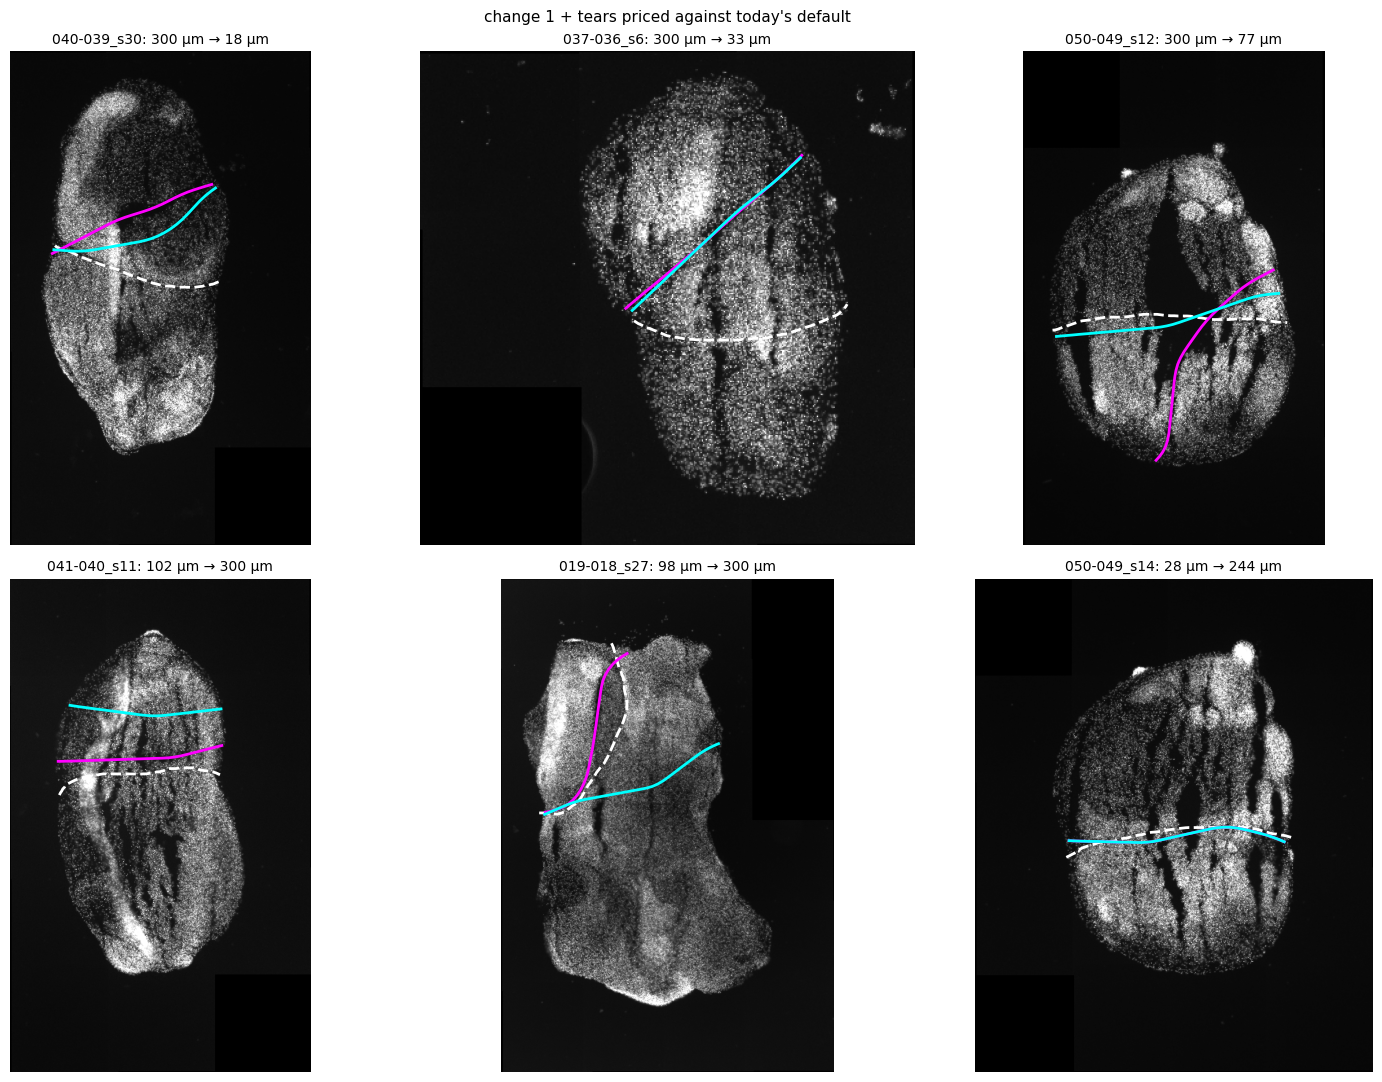

In [9]:
cand = min((v for v in LV if v != "default"), key=lambda v: lw[v][~held].mean())
change = (lw[cand] - lw["default"]).dropna().sort_values()
fig, axes = plt.subplots(2, 3, figsize=(16, 11))
for ax, name in zip(axes.ravel(), list(change.index[:3]) + list(change.index[-3:])):
    ov, band, manual, base = jt.load_case(name)
    stain = ov.channels[ov.nuclear].astype(float)
    ax.imshow(stain, cmap="gray", vmax=np.percentile(stain, 99.5))
    m = manual / ov.um
    ax.plot(m[:, 1], m[:, 0], "w--", lw=2)
    for variant, colour in (("default", "magenta"), (cand, "cyan")):
        r = jt.run_case((name, {**jt.defaults(), **jl.VARIANTS[variant]}))
        if r.get("line"):
            l = np.asarray(r["line"]) / ov.um
            ax.plot(l[:, 1], l[:, 0], color=colour, lw=2)
    ax.set_title(f"{name.split('_')[-2]}_{name.split('_')[-1]}: {lw.loc[name, 'default']:.0f} µm → {lw.loc[name, cand]:.0f} µm", fontsize=10)
    ax.set_axis_off()
fig.suptitle(f"{cand} against today's default", fontsize=11)
fig.tight_layout()
plt.show()

### What it showed (27 October 2026)

**The label change helps a little, and not reliably enough to switch on.** Against today's default (held-out 159 µm, 60 % bad lines):

- **Strength 1** (50 µm) is the best setting of the label term alone: held-out 146 µm, median and bad lines down, but the tuning sections do not improve (131 against 130 µm) and as many sections break as are fixed (20 / 20). Strength 0.5 does almost nothing; strength 2 breaks the first 30 (66 → 77 µm). Measured at 25 µm is about the same as 50 µm; at 100 µm it is worse (the valley is too wide to place a line).
- **It needs the no-seam fallback**: without it, strength 1 is worse than today (147 against 139 µm on all).
- **With tears priced** it is the best on the tuning sections by far (130 → 118 µm, median 97 → 65 µm, bad lines 48 → 35 %), as expected: the label term pulls the cut to the change, the tear price stops a dark tear from pulling it away. On the held-out sections it is much less clear: 159 → 154 µm (p 0.67), bad lines 60 → 51 %, 7 sections fixed against 8 broken. Tears priced alone gives held-out 150 µm.
- None of them changes the first 30 (sections with a dark line) by more than a few µm, except strength 2.

**Decision: left off** (`label_change` = 0, `tear_price` = 0). Every variant moves the bad-line share the right way, but the held-out mean improves by less than its noise and fixes balance breaks; the project's rule wants a clear held-out gain. The option stays in the engine (`JunctionOptions.label_change`, `label_change_um`), to switch on together with `tear_price = 1` for slides without dark lines, where it does best — check the QC pictures if you do.

**Why not more.** The pictures of the price show it: the label factor is not one valley along the junction but a map of **rings** — every patch of labelled cells, and every gap in one, has a steep edge, and the junction is only one of these edges, often not the steepest. The densities are smooth by nature (cells counted, then spread), so each edge is also tens of µm wide. The term can pull a cut towards the junction where nothing else does, but it adds as many wrong roads as right ones. More hand-drawn sections of the seamless kind, or a sharper label boundary (from the segmented cells rather than a density), would be the next steps.

## 7. Settings for sections with and without a dark line, chosen separately (27 October 2026)

Sections with a dark line at the junction and sections without one fail for different reasons, so each class may want its own settings. The finder can already tell them apart while it runs: the **seam price** of its first cut (> 0.4: no dark line). Since today the no-seam fallback is a second full set of settings (`no_seam_seed_rule`, `no_seam_lead`, `no_seam_label_change`, `no_seam_tear_price`, `no_seam_bend_um`, `no_seam_edge`), used only where the first cut found no line.

`junction_classes.py` runs every combination of five settings (seeds core / dominant with lead 0.35; label change 0 / 1; tears free / priced; bend 400 / 1000 µm; cells' edge 0 / 0.5 — 32 in all) on every section, the whole section with one set of settings → `classes.jsonl`. Each section's class is its seam price with today's first cut (`seeding_diagnostics.csv`): 78 with a line (51 tuning / 27 held out), 60 without (42 / 18). Per class, the combination is chosen on that class's **tuning** sections only.

with a dark line: 51 tuning / 27 held-out sections; today 115 / 135 µm


,tuning,held out,"bad lines, held out (%)"
combo,,,
dominant | change 1 | tears 1 | bend 1000 | edge 0,91.3,125.6,48.1
dominant | change 1 | tears 0 | bend 400 | edge 0,93.3,110.3,40.7
dominant | change 1 | tears 0 | bend 1000 | edge 0,95.7,125.4,48.1
dominant | change 1 | tears 1 | bend 400 | edge 0,100.1,113.7,40.7
dominant | change 0 | tears 0 | bend 400 | edge 0,105.7,110.8,33.3
dominant | change 0 | tears 1 | bend 1000 | edge 0,108.0,111.6,44.4


without a dark line: 42 tuning / 18 held-out sections; today 148 / 194 µm


,tuning,held out,"bad lines, held out (%)"
combo,,,
dominant | change 1 | tears 1 | bend 400 | edge 0,128.1,185.4,55.6
dominant | change 1 | tears 0 | bend 400 | edge 0,132.8,190.3,55.6
dominant | change 0 | tears 0 | bend 400 | edge 0,133.4,183.3,55.6
core | change 0 | tears 1 | bend 400 | edge 0,133.8,210.0,72.2
dominant | change 0 | tears 1 | bend 400 | edge 0,134.6,173.1,50.0
dominant | change 0 | tears 1 | bend 1000 | edge 0,135.3,173.4,55.6


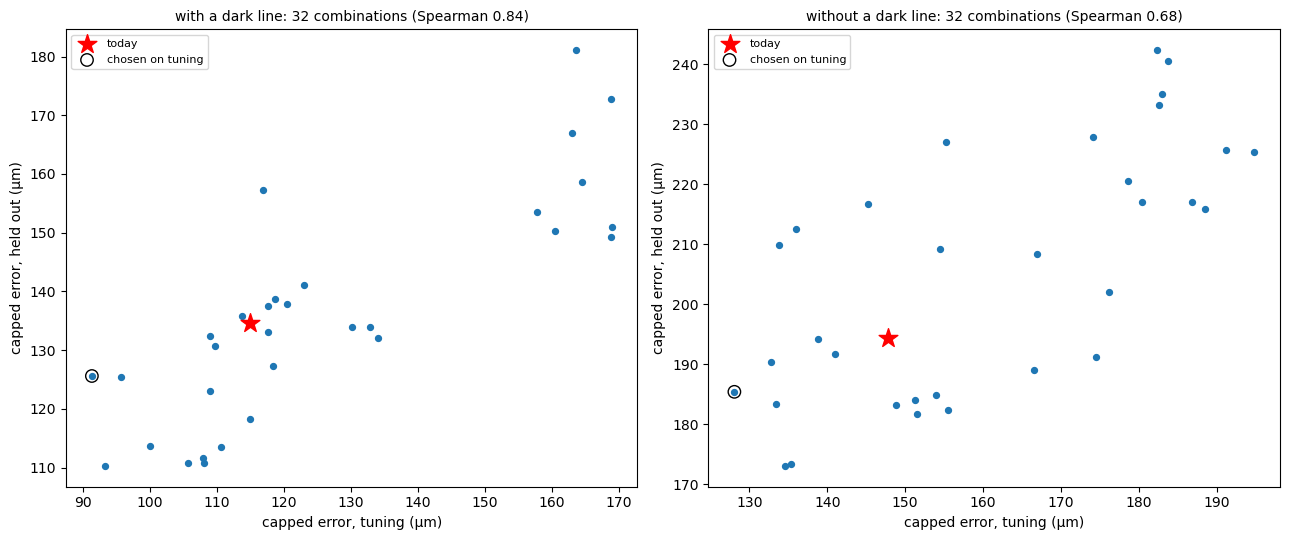

In [10]:
g = pd.read_json(OUT / "classes.jsonl", lines=True)
g["combo"] = g.apply(lambda r: f"{r.seed_rule} | change {r.label_change:g} | tears {r.tear_price:g} | bend {r.bend_um:g} | edge {r.edge_weight:g}", axis=1)
cw = g.pivot(index="name", columns="combo", values="capped")
cd = diag.set_index("name").reindex(cw.index)
c_held = cd["set"] == "held out"
c_first = cd["batch"] == "first 31"
no_line = cd["Seam price"] > jn.NO_SEAM_PRICE
lab_default = lab[lab["variant"] == "default"].set_index("name")["capped"].reindex(cw.index)
winners = {}
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (cls, m) in zip(axes, (("with a dark line", ~no_line), ("without a dark line", no_line))):
    tune, hold = cw[m & ~c_held].mean(), cw[m & c_held].mean()
    order = tune.sort_values().index
    winners[cls] = order[0]
    print(f"{cls}: {int((m & ~c_held).sum())} tuning / {int((m & c_held).sum())} held-out sections; "
          f"today {lab_default[m & ~c_held].mean():.0f} / {lab_default[m & c_held].mean():.0f} µm")
    display(pd.DataFrame({"tuning": tune[order], "held out": hold[order],
                          "bad lines, held out (%)": (cw[m & c_held] > BAD).mean()[order] * 100}).head(6).round(1))
    ax.scatter(tune, hold, s=18)
    ax.scatter([lab_default[m & ~c_held].mean()], [lab_default[m & c_held].mean()], marker="*", s=200, c="red", label="today")
    ax.scatter([tune[order[0]]], [hold[order[0]]], s=80, facecolors="none", edgecolors="black", label="chosen on tuning")
    ax.set_xlabel("capped error, tuning (µm)"); ax.set_ylabel("capped error, held out (µm)")
    ax.set_title(f"{cls}: 32 combinations (Spearman {stats.spearmanr(tune, hold)[0]:.2f})", fontsize=10)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The two choices put together (each class gets its own winner), against today, and two simpler alternatives: the winner of the "with a line" class everywhere, and today's first cut with the "without a line" winner as the second search (what the engine's no-seam settings would give). The **first 30** are the sections of the original evaluation (most have a clear line).

In [11]:
def per_class(line_combo, no_line_combo):
    return pd.Series(np.where(no_line, cw[no_line_combo], cw[line_combo]), index=cw.index)

plain = "core | change 0 | tears 0 | bend 1000 | edge 0"
options_ = {"today": lab_default,
            "each class its own winner": per_class(winners["with a dark line"], winners["without a dark line"]),
            "the with-line winner everywhere": cw[winners["with a dark line"]],
            "today's first cut, without-line winner second": per_class(plain, winners["without a dark line"])}
rows = {}
for k, s in options_.items():
    c = s - lab_default
    rows[k] = {"tuning": s[~c_held].mean(), "held out": s[c_held].mean(), "first 30": s[c_first].mean(), "new 108": s[~c_first].mean(),
               "bad lines, held out (%)": (s[c_held] > BAD).mean() * 100,
               "fixed / broken, held out": f"{int((c[c_held] < -25).sum())} / {int((c[c_held] > 25).sum())}",
               "Wilcoxon p, held out": stats.wilcoxon(c[c_held]).pvalue if (c[c_held] != 0).any() else np.nan}
print("chosen:", winners)
display(pd.DataFrame(rows).T.round(3))

chosen: {'with a dark line': 'dominant | change 1 | tears 1 | bend 1000 | edge 0', 'without a dark line': 'dominant | change 1 | tears 1 | bend 400 | edge 0'}


,tuning,held out,first 30,new 108,"bad lines, held out (%)","fixed / broken, held out","Wilcoxon p, held out"
today,129.747584,158.580324,66.249877,159.399478,60.0,0 / 0,NaN
each class its own winner,107.927685,149.53406,80.351051,132.923851,51.111111,11 / 9,0.285377
the with-line winner everywhere,113.755121,152.07186,82.866175,138.300692,53.333333,9 / 9,0.489399
"today's first cut, without-line winner second",120.836458,154.95883,68.359476,149.631052,53.333333,3 / 3,0.58292


### What it showed (27 October 2026)

**Choosing settings per class helps the tuning sections a lot and the held-out ones little; it is not switched on.**

- The rankings carry over from tuning to held-out reasonably (Spearman 0.84 with a line, 0.68 without), so the comparison is not noise.
- **Both classes choose dominant seeds and no cells' edge**, with the label change and priced tears; they differ only in the bend (1000 µm with a line, 400 without). So the split by dark line mostly picks the bend.
- Together: tuning 130 → 108 µm, held out 159 → 150 µm (p 0.29; 11 sections fixed, 9 broken), bad held-out lines 60 → 51 %. But the **first 30 get worse, 66 → 80 µm**: they have a dark line *and* clean labels, and on them today's core seeds are better than dominant ones. The seam price does not separate the sections where today's seeds work from those where they fail.
- Today's first cut with the "without a line" winner as the second search changes little (held out 155 µm, first 30 68 µm).

**Decision: defaults unchanged.** The engine keeps the second set of settings (`no_seam_*` in `JunctionOptions`, defaults = today's fallback), so a run on slides without dark lines can use its own seeds and price. What would decide better than the seam price is whether the **core seeds are trustworthy** — clean labels, one dominant AF488 patch — and that needs more hand-drawn sections where they fail, to learn it without overfitting. Until then: triage (fail, Damaged, *no dark line at the junction*) and hand-drawing.